# Homework 5 Worked Example: Tennessee County Corn Yields

### AGEC 370: Agricultural Price Analysis

Click the badge below to open in Google Colab:

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/chuckgrigsby0/agec_370/blob/main/code/notebooks/hw05_example_corn_county_yields.ipynb)

---

## Objective

Map the average corn yield of each Tennessee county and summarize the yields by USDA NASS agricultural district (a group of neighboring counties). Use a regression with dummy variables to estimate how much each district differs from West Tennessee.

---

## How to Use This Notebook

1. Save a copy of this notebook to your Google Drive.
2. Run every cell in order from top to bottom.
3. Read the comments above each step before running the code. Review the output after running code cells.
4. Open the [Homework 5 notebook](https://colab.research.google.com/github/chuckgrigsby0/agec_370/blob/main/code/notebooks/hw05_soybean_county_yields.ipynb). Complete the same steps with the soybean yield data.

## Data Description

The file `tn_county_yields.csv` has one row per crop, county, and year, 2015 to 2025. A county has a row only in years when NASS published its yield, so many counties are missing in each year.

| Column | Description | Units |
|---|---|---|
| `crop` | Crop name: `corn` or `soybeans` | |
| `fips` | County code: state code 47 followed by a three-digit county code | |
| `county` | County name | |
| `district` | USDA NASS agricultural district | |
| `year` | Calendar year | |
| `yield_bu_acre` | Yield per harvested acre (USDA NASS) | Bushels per acre |

The file `tn_counties.geojson` has one row per Tennessee county, 95 in all. It holds the county boundaries, including counties with no yield data.

| Column | Description | Units |
|---|---|---|
| `fips` | County code, as in the yield file | |
| `county` | County name | |
| `district` | USDA NASS agricultural district | |
| `geometry` | County boundary | Longitude and latitude |

## Package and Data Loading

Import the libraries and load both files. The `fips` code is read as text so it matches the code in the boundary file.

In [1]:
# Import data manipulation libraries
import pandas as pd
import numpy as np

# Import mapping libraries
# 'geopandas' reads boundary files and plots maps. 'plotly' makes interactive maps.
import geopandas as gpd
import json
import plotly.express as px
import plotly.graph_objects as go

# Import visualization libraries
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
import seaborn as sns

# Import the regression library
# 'smf' lets us write a regression as a formula, such as 'outcome ~ explanatory variable'
import statsmodels.formula.api as smf

In [2]:
# Load data from GitHub repository
base_url = "https://raw.githubusercontent.com/chuckgrigsby0/agec_370/main/data/hw/"

# fips is read as text so the county codes match the codes in the boundary file
yields = pd.read_csv(base_url + "tn_county_yields.csv", dtype={'fips': str})
counties = gpd.read_file(base_url + "tn_counties.geojson")

# Keep the rows for one crop.
corn_yields = yields[yields['crop'] == 'corn'].copy()

corn_yields.head()

,crop,fips,county,district,year,yield_bu_acre
0,corn,47003,Bedford,Central Basin,2016,147.2
1,corn,47003,Bedford,Central Basin,2017,175.0
2,corn,47003,Bedford,Central Basin,2018,160.0
3,corn,47003,Bedford,Central Basin,2019,168.0
4,corn,47003,Bedford,Central Basin,2020,142.7


In [3]:
# Check: this cell runs without an error when both files loaded correctly
assert counties.shape[0] == 95, "The county file should have one row for each of the 95 Tennessee counties."
assert set(['fips', 'county', 'district', 'year', 'yield_bu_acre']).issubset(corn_yields.columns), "A column is missing from the yield data."
assert corn_yields['crop'].nunique() == 1, "Keep the rows for one crop."
print("Data loaded correctly.")

Data loaded correctly.


### Predict the Highest District

**Predict before you compute.** In the homework, you will record a guess here: which of the six districts do you expect to have the highest average corn yield? Then compare the guess with the result.

## County Averages

Yields change with the weather, so one year can mislead. NASS also publishes a county yield only when enough farms report, so each year has a different set of counties. We use each county's average over 2019 to 2023 and keep counties with a yield in at least 3 of those 5 years.

`.groupby()` splits a table into one group per county, and `.agg()` calculates one number for each group.

In [4]:
first_year = 2019
last_year = 2023
min_years = 3

# Keep the rows from the first year through the last year.
recent = corn_yields[corn_yields['year'].between(first_year, last_year)]

In [5]:
# One row per county: the average yield and the number of years with a yield
county_avg = (
    recent
    .groupby(['fips', 'county', 'district'], as_index=False)
    .agg(
        avg_yield=('yield_bu_acre', 'mean'),
        years=('year', 'count')
    )
)

# Keep counties with at least the minimum number of years.
county_avg = county_avg[county_avg['years'] >= min_years]

print(f"Counties kept: {len(county_avg)}")
county_avg.head()

Counties kept: 55


,fips,county,district,avg_yield,years
0,47003,Bedford,Central Basin,155.900000,5
1,47005,Benton,West Tennessee,158.366667,3
2,47007,Bledsoe,Cumberland Plateau,166.040000,5
3,47009,Blount,East Tennessee,146.220000,5
6,47015,Cannon,Central Basin,169.800000,5


In [6]:
# Check: this cell runs without an error when each county appears once and has enough years
assert len(county_avg) > 0, "No counties are left. Check the first year, the last year, and the minimum number of years."
assert county_avg['fips'].is_unique, "Each county should appear once."
assert (county_avg['years'] >= min_years).all(), "Keep only counties with at least the minimum number of years."
assert (county_avg['years'] <= last_year - first_year + 1).all(), "A county cannot have more years than the period holds. Check the first and last year."
assert county_avg['avg_yield'].notna().all(), "Every county should have an average yield."
check_means = recent.groupby('fips')['yield_bu_acre'].mean().reindex(county_avg['fips']).values
assert np.allclose(county_avg['avg_yield'], check_means), "Each average yield should be the mean of that county's yearly yields."
print("County averages are correct.")

County averages are correct.


## Summary Statistics by District

Group the county averages by district to compare the districts.

In [7]:
# Summary statistics of the county averages for each district.
district_summary = (
    county_avg
    .groupby('district')['avg_yield']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(1)
)
district_summary

,count,mean,median,std,min,max
district,,,,,,
Central Basin,10,167.3,167.9,9.6,155.3,185.0
Cumberland Plateau,10,169.4,175.1,11.6,152.2,182.1
Delta,5,164.6,164.2,3.5,160.0,169.0
East Tennessee,9,152.7,157.1,12.1,127.5,168.3
West Tennessee,14,158.8,159.5,9.1,135.8,173.9
Western Rim,7,162.3,167.6,12.5,141.6,174.2


In [8]:
# Look up the West Tennessee mean in the table above.
west_tn_mean = district_summary.loc['West Tennessee', 'mean']

highest_district = district_summary['mean'].idxmax()

print(f"West Tennessee mean: {west_tn_mean} (bushels per acre)")
print(f"District with the highest mean: {highest_district}")

West Tennessee mean: 158.8 (bushels per acre)
District with the highest mean: Cumberland Plateau


In [9]:
# Check: this cell runs without an error when the values match the table above
assert np.isclose(west_tn_mean, county_avg.loc[county_avg['district'] == 'West Tennessee', 'avg_yield'].mean(), atol=0.06), "The West Tennessee mean should come from the West Tennessee row of the table."
assert district_summary.loc[highest_district, 'mean'] == district_summary['mean'].max(), "The district with the highest mean should have the largest value in the mean column."
print("Values match the table.")

Values match the table.


### Bar Chart of District Means

Visualize the mean of the county averages (bushels per acre) for each district.

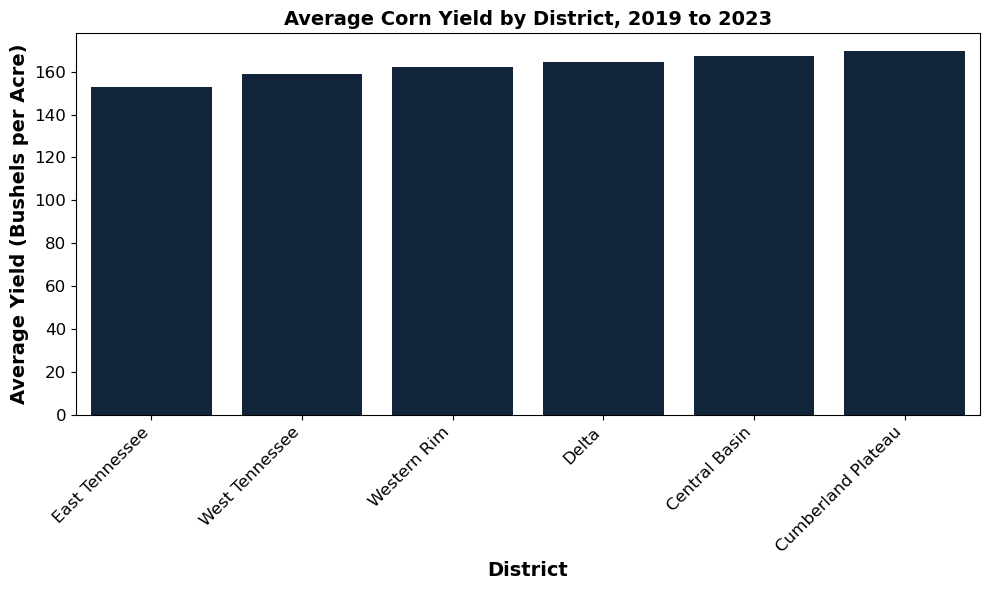

In [10]:
district_plot = district_summary.reset_index().sort_values('mean')  # smallest mean on the left

plt.figure(figsize=(10, 6))

sns.barplot(
    data=district_plot,
    x='district',         # Plot the district on the x-axis
    y='mean',         # Plot the district mean on the y-axis
    color='#0b2341'       # Bar color
)

plt.title("Average Corn Yield by District, 2019 to 2023", fontsize=14, weight='bold')
plt.xlabel("District", fontsize=14, weight='bold')

plt.ylabel("Average Yield (Bushels per Acre)", fontsize=14, weight='bold')

plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

## Static Map

A *choropleth map* shades each area by a value. First merge the county averages onto the county boundaries. A *left join* keeps every row of the first table, so the counties with no average yield stay in the file and appear on the map in gray.

**Predict before you look.** Which part of the state do you expect to have the most gray counties?

In [11]:
# Merge the county averages onto the boundaries.
# The quotes are already there.
map_data = counties.merge(county_avg[['fips', 'avg_yield', 'years']], on='fips', how='left')

# Count the counties with no average yield.
n_missing = map_data['avg_yield'].isna().sum()
print(f"Counties with no average yield: {n_missing}")

Counties with no average yield: 40


In [12]:
# Check: this cell runs without an error when the merge kept every county
assert len(map_data) == len(counties), "The merge should keep all 95 counties."
assert map_data['fips'].is_unique, "Each county should appear once."
print("Merge is correct.")

Merge is correct.


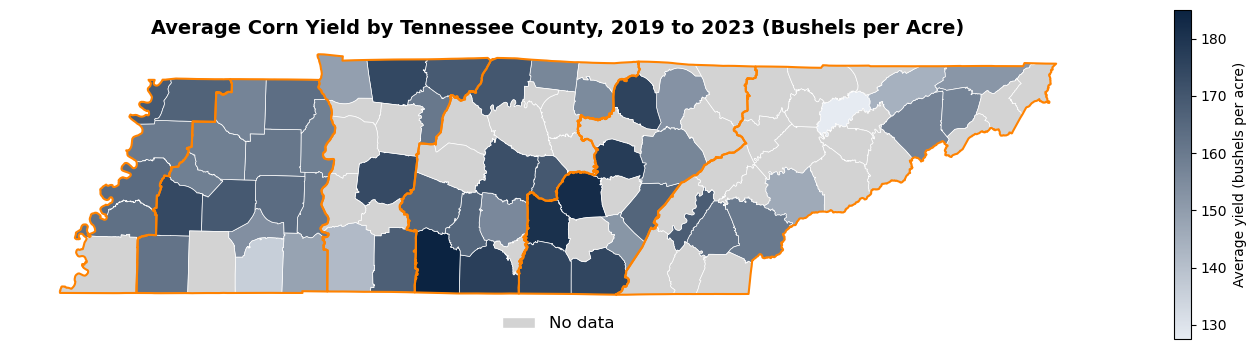

In [13]:
# A color scale from light blue-gray to navy: darker counties have higher yields
navy_scale = LinearSegmentedColormap.from_list('navy_scale', ['#e6ebf2', '#0b2341'])

fig, ax = plt.subplots(figsize=(14, 5))

map_data.plot(
    column='avg_yield',
    cmap=navy_scale,
    edgecolor='white',     # County borders
    linewidth=0.5,
    legend=True,
    legend_kwds={'label': 'Average yield (bushels per acre)', 'shrink': 0.7},
    missing_kwds={'color': 'lightgray'},  # Counties with no average yield
    ax=ax
)

# Draw the district borders in orange to compare the counties within each district
map_data.dissolve(by='district').boundary.plot(ax=ax, color='#FF8200', linewidth=1.5)

# Label the gray counties
ax.legend(handles=[Patch(facecolor='lightgray', edgecolor='white', label='No data')], loc='upper center', bbox_to_anchor=(0.5, 0.02), frameon=False, fontsize=12)

plt.title("Average Corn Yield by Tennessee County, 2019 to 2023 (Bushels per Acre)", fontsize=14, weight='bold')
ax.set_axis_off()
plt.tight_layout()
plt.show()

## Interactive Map

An interactive map shows the values when you move the cursor over a county. `px.choropleth()` needs two things: a table of values and the county boundaries in GeoJSON format. The argument `featureidkey` names the property in the boundaries that matches the `locations` column in the table.

You do not need to write or understand the code that adds the gray layer. Hover over a county to read its name, district, average yield, and the number of years behind the average.

Documentation: [Plotly choropleth maps](https://plotly.com/python/choropleth-maps/)

In [14]:
# Convert the county boundaries to the GeoJSON format that plotly reads
geojson = json.loads(counties.to_json())

fig = px.choropleth(
    county_avg,                          # Table of values: one row per county with an average yield
    geojson=geojson,                     # County boundaries
    locations='fips',                    # Column in the table that identifies each county
    featureidkey='properties.fips',      # Property in the boundaries that holds the same code
    color='avg_yield',
    hover_name='county',
    hover_data={'district': True, 'avg_yield': ':.1f', 'years': True, 'fips': False},
    color_continuous_scale=['#e6ebf2', '#0b2341'],
    labels={'avg_yield': 'Yield (bu/acre)', 'years': 'Years of data', 'district': 'District'}
)

# Add the counties with no average yield as a gray layer, so they stay on the map
no_data = map_data[map_data['avg_yield'].isna()]
fig.add_trace(go.Choropleth(
    geojson=geojson,
    locations=no_data['fips'],
    featureidkey='properties.fips',
    z=[0] * len(no_data),
    colorscale=[[0, 'lightgray'], [1, 'lightgray']],
    showscale=False,
    marker_line_color='white',
    hovertext=no_data['county'] + ' (no data)',
    hoverinfo='text'
))

fig.update_geos(fitbounds='locations', visible=False)  # Zoom to Tennessee and hide the world map

fig.update_layout(
    title_text="Average Corn Yield by Tennessee County, 2019 to 2023",
    margin=dict(l=0, r=0, t=50, b=0)
)
fig.show()

In [15]:
# Check: this cell runs without an error when the figure has the county layer and the gray layer
assert len(fig.data) == 2, "The figure should have a layer for counties with data and a layer for counties with no data."
assert fig.data[0].locations is not None and len(fig.data[0].locations) == len(county_avg), "The first layer should have one location for each county with data."
print("Interactive map is ready.")

Interactive map is ready.


## Regression with District Dummy Variables

A *dummy variable* equals 1 for the counties in one district and 0 for all other counties. A regression with a dummy variable for every district except one compares each district with the district left out, the *reference district*. We use the district of UT Martin as the reference.

`C(district, Treatment(reference=...))` creates the dummy variables for us. Read the results this way:

- The *intercept* is the mean of the county averages in the reference district.
- Each *coefficient* is the difference between that district's mean of county averages and the reference district's mean (bushels per acre).
- The *p-value* is the probability of an estimate at least this far from zero, in either direction, if the true difference were zero. A p-value below 0.05 is the usual cutoff for calling a difference statistically significant.
- The *R-squared* is the share of the variation in county averages that the districts explain.

Each district has only a few counties with an average yield, so a difference can be real and still not statistically significant. A small or non-significant difference is a valid result.

**Predict before you run it.** Use the district means in the summary table. What should the East Tennessee coefficient equal, in terms of two of the district means? Which districts do you expect to differ from the reference by more than a few bushels per acre, and which differences do you expect to be statistically significant?

In [16]:
# Store the district as a category, so the formula reads it as a set of groups
regression_data = county_avg.assign(district=county_avg['district'].astype('category'))

# Regress each county's average yield on its district.
# The quotes are already there.
dummy_model = smf.ols("avg_yield ~ C(district, Treatment(reference='West Tennessee'))", data=regression_data).fit()

# Collect the coefficients and p-values in one table.
# The regex keeps only the district name from labels such as C(district, ...)[T.East Tennessee].
# You only need the table it creates.
results = pd.DataFrame({'coefficient': dummy_model.params, 'p_value': dummy_model.pvalues})
results.index = results.index.str.replace(r"C\(.*\)\[T\.(.*)\]", r"\1", regex=True)
results.round(3)

,coefficient,p_value
Intercept,158.839,0.000
Central Basin,8.500,0.053
Cumberland Plateau,10.559,0.018
Delta,5.727,0.295
East Tennessee,-6.115,0.174
Western Rim,3.508,0.469


In [17]:
# Check: this cell runs without an error when the reference district is West Tennessee
west_mean_check = county_avg.loc[county_avg['district'] == 'West Tennessee', 'avg_yield'].mean()
assert np.isclose(results.loc['Intercept', 'coefficient'], west_mean_check), "The reference district should be the district of UT Martin."
assert 'West Tennessee' not in results.index, "West Tennessee is the reference district, so it has no coefficient."
print("Reference district is correct.")

Reference district is correct.


In [18]:
# Pull values from the table above
intercept = results.loc['Intercept', 'coefficient']

east_coef = results.loc['East Tennessee', 'coefficient']
east_p = results.loc['East Tennessee', 'p_value']

# The East Tennessee mean minus the reference mean, calculated from the county averages
east_diff = county_avg.loc[county_avg['district'] == 'East Tennessee', 'avg_yield'].mean() - west_mean_check

r2 = dummy_model.rsquared

# Count the districts that differ from West Tennessee at the 0.05 level.
n_significant = (results.drop('Intercept')['p_value'] < 0.05).sum()

print(f"Intercept: {intercept:.1f} (bushels per acre)")
print(f"East Tennessee coefficient: {east_coef:.1f}, p-value {east_p:.3f}")
print(f"East Tennessee mean minus the reference mean: {east_diff:.1f}")
print(f"R-squared: {r2:.3f}")
print(f"Districts different from West Tennessee at 0.05: {n_significant}")

Intercept: 158.8 (bushels per acre)
East Tennessee coefficient: -6.1, p-value 0.174
East Tennessee mean minus the reference mean: -6.1
R-squared: 0.252
Districts different from West Tennessee at 0.05: 1


In [19]:
# Check: this cell runs without an error when the values come from the regression table
assert np.isclose(east_coef, east_diff, atol=0.06), "A coefficient should equal that district's mean minus the reference district's mean."
assert 0 <= r2 <= 1, "R-squared is a share, so it lies between 0 and 1."
print("Regression values are correct.")

Regression values are correct.


### Interpreting the Corn Results

Compare the size of a coefficient with its p-value. A coefficient with a p-value above 0.05 may be a real difference, but the data cannot tell it apart from zero.

Changing the reference district changes every coefficient, but not the districts' means. If Delta were the reference, the intercept would be the Delta mean, and each new coefficient would be the old coefficient minus the old Delta coefficient. The cell below shows this for East Tennessee.

The gray counties on the maps are not spread evenly across the districts. A district with many gray counties has a mean based on fewer counties.

The R-squared is the share of the variation in county averages that the districts explain. The rest is variation among counties within the same district, which shows as changes in shade inside the orange district borders.

In [20]:
# East Tennessee compared with Delta, using the coefficients from the table above
delta_coef = results.loc['Delta', 'coefficient']
print(f"East Tennessee compared with the reference district: {east_coef:.1f} (bushels per acre)")
print(f"East Tennessee compared with Delta: {east_coef - delta_coef:.1f} (bushels per acre)")

East Tennessee compared with the reference district: -6.1 (bushels per acre)
East Tennessee compared with Delta: -11.8 (bushels per acre)


### Summary of Answers

Run the cell below to print the answers in one table.

In [21]:
# Collect the answers computed above in one table
summary = pd.Series({
    'Rows in the corn yield data': len(corn_yields),
    'Counties in the county file': len(counties),
    'Counties kept (at least 3 years)': len(county_avg),
    'Counties with no average yield': n_missing,
    'District with the highest mean': highest_district,
    'West Tennessee mean (bushels per acre)': round(west_tn_mean, 1),
    'Intercept (bushels per acre)': round(intercept, 1),
    'East Tennessee coefficient (bushels per acre)': round(east_coef, 1),
    'East Tennessee p-value': round(east_p, 3),
    'R-squared': round(r2, 3),
    'Districts different from West Tennessee at 0.05': int(n_significant),
}, name='Answer', dtype=object)  # object type keeps whole numbers as whole numbers
summary.to_frame()

,Answer
Rows in the corn yield data,578
Counties in the county file,95
Counties kept (at least 3 years),55
Counties with no average yield,40
District with the highest mean,Cumberland Plateau
West Tennessee mean (bushels per acre),158.8
Intercept (bushels per acre),158.8
East Tennessee coefficient (bushels per acre),-6.1
East Tennessee p-value,0.174
R-squared,0.252
